# CT107-3-3 Text Analytics & Sentiment Analysis
## Part B — Supervised Text Classification

In [1]:
# Imports
import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

print("Libraries loaded.")

Libraries loaded.


---
## Q1 — Dataset & Exploratory Data Analysis

### Q1.1 Literature Review

See report Section 6.2 for full literature review and dataset justification.

In [2]:
# Load the dataset
df = pd.read_csv('data.csv')

print(f"Shape: {df.shape}")
print()
df.head()

Shape: (50000, 2)



,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Quick look at structure and class balance
df.info()
print()
print(df['sentiment'].value_counts())
print()
print("Nulls:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Nulls: 0
Duplicates: 418


In [4]:
# Text preprocessing
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

# Vectorized cleaning steps
clean = df['review'].str.lower()
clean = clean.str.replace(r'<.*?>', ' ', regex=True)           # html tags
clean = clean.str.replace(r'http\S+|www\.\S+', '', regex=True) # urls
clean = clean.str.replace(r'[^\w\s]', '', regex=True)          # punctuation
clean = clean.str.replace(r'\d+', '', regex=True)              # numbers
clean = clean.str.replace(r'\s+', ' ', regex=True).str.strip()

# Stemming still needs to be done per-row unfortunately
def stem_and_filter(text):
    return ' '.join(ps.stem(w) for w in text.split() if w not in stop_words)

print("Preprocessing...")
df['clean_review'] = clean.apply(stem_and_filter)
print("Done.")

# Before vs after
print("\nOriginal:")
print(df['review'].iloc[0][:300])
print("\nCleaned:")
print(df['clean_review'].iloc[0][:300])

Preprocessing...


Done.

Original:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

Cleaned:
one review mention watch oz episod youll hook right exactli happen first thing struck oz brutal unflinch scene violenc set right word go trust show faint heart timid show pull punch regard drug sex violenc hardcor classic use word call oz nicknam given oswald maximum secur state penitentari focus ma


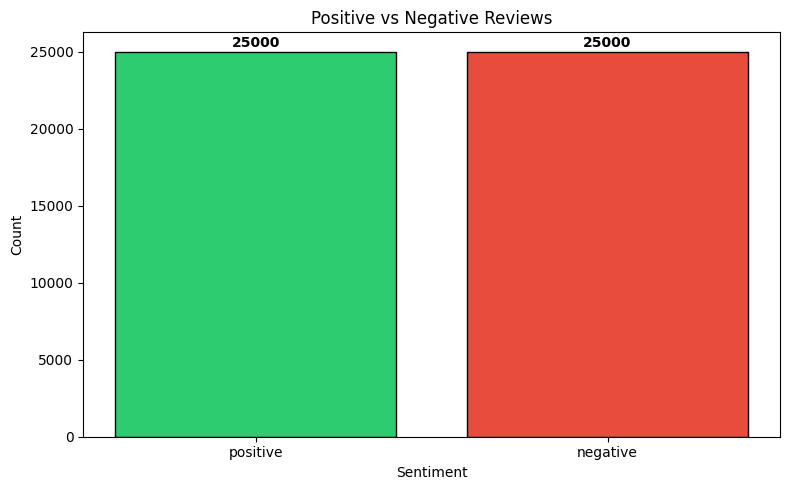

In [5]:
# Class distribution
fig, ax = plt.subplots(figsize=(8, 5))
counts = df['sentiment'].value_counts()
ax.bar(counts.index, counts.values, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Positive vs Negative Reviews')
ax.set_xlabel('Sentiment')
ax.set_ylabel('Count')
for i, v in enumerate(counts.values):
    ax.text(i, v + 300, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

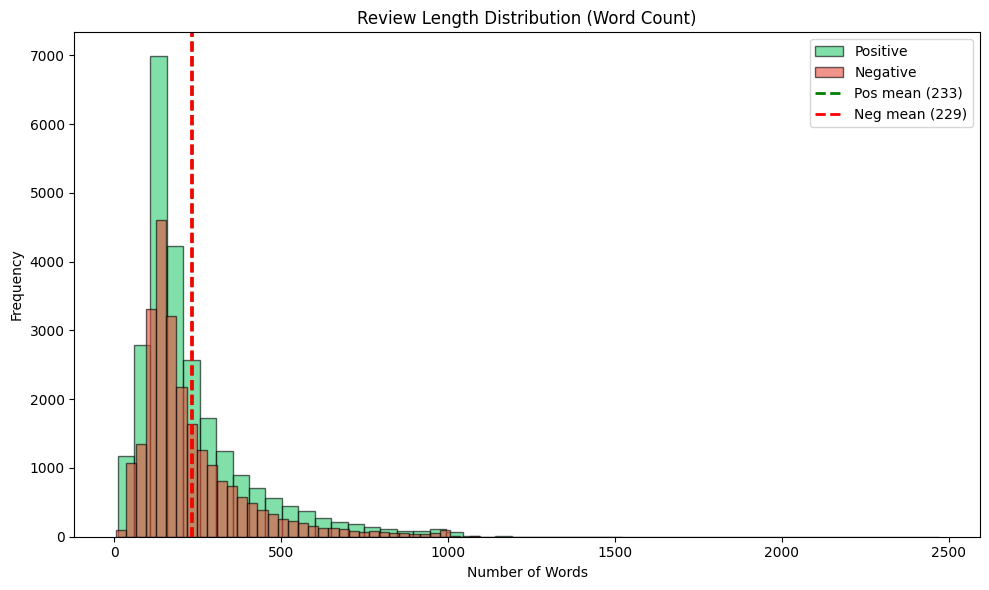

In [6]:
# Review length distribution
df['word_count'] = df['review'].str.split().str.len()

pos_lengths = df.loc[df['sentiment'] == 'positive', 'word_count']
neg_lengths = df.loc[df['sentiment'] == 'negative', 'word_count']

plt.figure(figsize=(10, 6))
plt.hist(pos_lengths, bins=50, alpha=0.6, label='Positive', color='#2ecc71', edgecolor='black')
plt.hist(neg_lengths, bins=50, alpha=0.6, label='Negative', color='#e74c3c', edgecolor='black')
plt.axvline(pos_lengths.mean(), color='green', linestyle='--', lw=2, label=f'Pos mean ({pos_lengths.mean():.0f})')
plt.axvline(neg_lengths.mean(), color='red', linestyle='--', lw=2, label=f'Neg mean ({neg_lengths.mean():.0f})')
plt.title('Review Length Distribution (Word Count)')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

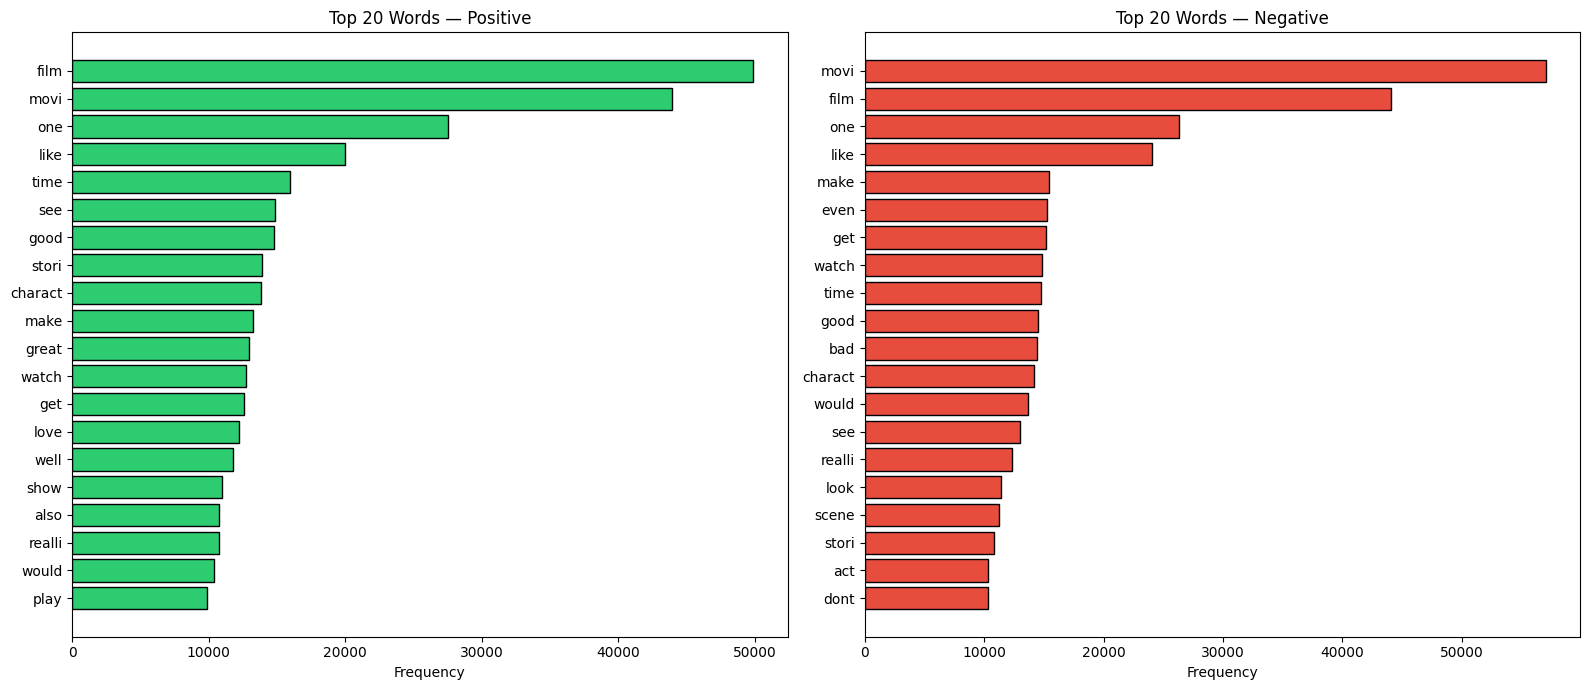

In [7]:
# Top 20 words per class (after preprocessing)
pos_counter = Counter()
neg_counter = Counter()
for review, sent in zip(df['clean_review'], df['sentiment']):
    if sent == 'positive':
        pos_counter.update(review.split())
    else:
        neg_counter.update(review.split())

pos_freq = pos_counter.most_common(20)
neg_freq = neg_counter.most_common(20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

ax1.barh([w for w, _ in pos_freq][::-1], [c for _, c in pos_freq][::-1], color='#2ecc71', edgecolor='black')
ax1.set_title('Top 20 Words — Positive')
ax1.set_xlabel('Frequency')

ax2.barh([w for w, _ in neg_freq][::-1], [c for _, c in neg_freq][::-1], color='#e74c3c', edgecolor='black')
ax2.set_title('Top 20 Words — Negative')
ax2.set_xlabel('Frequency')

plt.tight_layout()
plt.show()

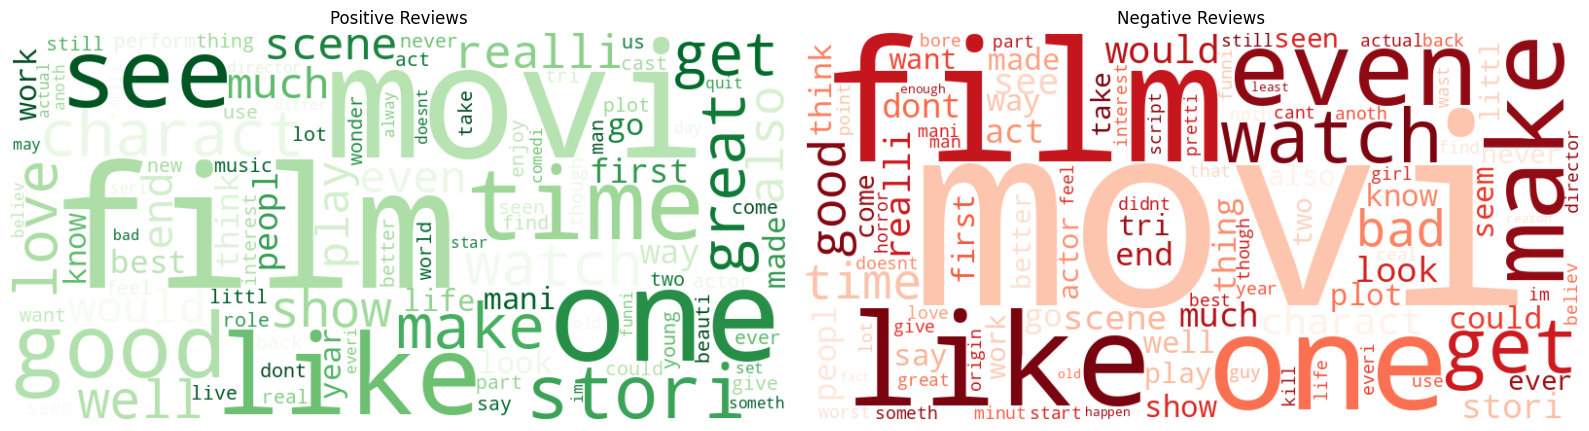

In [8]:
# Word clouds
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

wc_pos = WordCloud(width=800, height=400, background_color='white',
                   colormap='Greens', max_words=100).generate_from_frequencies(pos_counter)
ax1.imshow(wc_pos, interpolation='bilinear')
ax1.set_title('Positive Reviews')
ax1.axis('off')

wc_neg = WordCloud(width=800, height=400, background_color='white',
                   colormap='Reds', max_words=100).generate_from_frequencies(neg_counter)
ax2.imshow(wc_neg, interpolation='bilinear')
ax2.set_title('Negative Reviews')
ax2.axis('off')

plt.tight_layout()
plt.show()

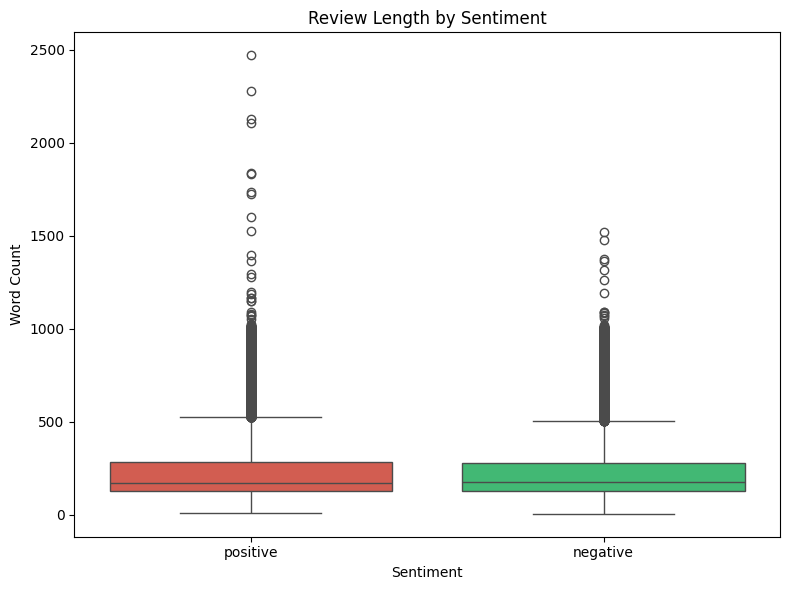

In [9]:
# Boxplot — review length by sentiment
plt.figure(figsize=(8, 6))
sns.boxplot(x='sentiment', y='word_count', data=df, palette=['#e74c3c', '#2ecc71'])
plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Word Count')
plt.tight_layout()
plt.show()

### Q1.5 — EDA Summary & Model Selection

Balanced dataset (25k per class), similar review lengths across classes, clear vocabulary separation between sentiments. Four models selected: Multinomial NB, Logistic Regression, Linear SVM, Random Forest. See report Sections 6.4–6.5.

---
## Q2 — Supervised Text Classification

In [10]:
# Train/test split — 80/20, stratified to keep class balance
X = df['clean_review']
y = df['sentiment'].map({'positive': 1, 'negative': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {X_train.shape[0]}, Test: {X_test.shape[0]}")
print(f"\nTrain distribution:\n{y_train.value_counts()}")
print(f"\nTest distribution:\n{y_test.value_counts()}")

Train: 40000, Test: 10000

Train distribution:
sentiment
1    20000
0    20000
Name: count, dtype: int64

Test distribution:
sentiment
0    5000
1    5000
Name: count, dtype: int64


In [11]:
# Build TF-IDF pipelines for all 4 models
tfidf_params = dict(max_features=10000, ngram_range=(1, 2),
                    stop_words='english', sublinear_tf=True)

pipelines = {
    'Naive Bayes': Pipeline([
        ('tfidf', TfidfVectorizer(**tfidf_params)),
        ('clf', MultinomialNB())
    ]),
    'Logistic Regression': Pipeline([
        ('tfidf', TfidfVectorizer(**tfidf_params)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Linear SVM': Pipeline([
        ('tfidf', TfidfVectorizer(**tfidf_params)),
        ('clf', LinearSVC(random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('tfidf', TfidfVectorizer(**tfidf_params)),
        ('clf', RandomForestClassifier(n_estimators=100, random_state=42))
    ])
}

# Train
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{name} trained.")

Naive Bayes trained.


Logistic Regression trained.


Linear SVM trained.


Random Forest trained.


### Q2.3 — Evaluation Metrics

Accuracy, Precision, Recall, and F1-Score (macro). All appropriate for this balanced binary dataset. See report Section 7.2.

In [12]:
# Evaluate all models on the test set
results = []

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec,
                    'Recall': rec, 'F1-Score': f1})

    print(f"\n{name}")
    print("-" * 40)
    print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

results_df = pd.DataFrame(results).set_index('Model')
print("\nSummary:")
print(results_df.round(4).to_string())


Naive Bayes
----------------------------------------
              precision    recall  f1-score   support

    Negative       0.88      0.85      0.86      5000
    Positive       0.85      0.88      0.87      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000




Logistic Regression
----------------------------------------
              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      5000
    Positive       0.89      0.91      0.90      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000




Linear SVM
----------------------------------------
              precision    recall  f1-score   support

    Negative       0.89      0.88      0.88      5000
    Positive       0.88      0.89      0.89      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000




Random Forest
----------------------------------------
              precision    recall  f1-score   support

    Negative       0.85      0.86      0.86      5000
    Positive       0.86      0.85      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000


Summary:
                     Accuracy  Precision  Recall  F1-Score
Model                                                     
Naive Bayes            0.8642     0.8645  0.8642    0.8642
Logistic Regression    0.8942     0.8944  0.8942    0.8942
Linear SVM             0.8846     0.8847  0.8846    0.8846
Random Forest          0.8567     0.8568  0.8567    0.8567


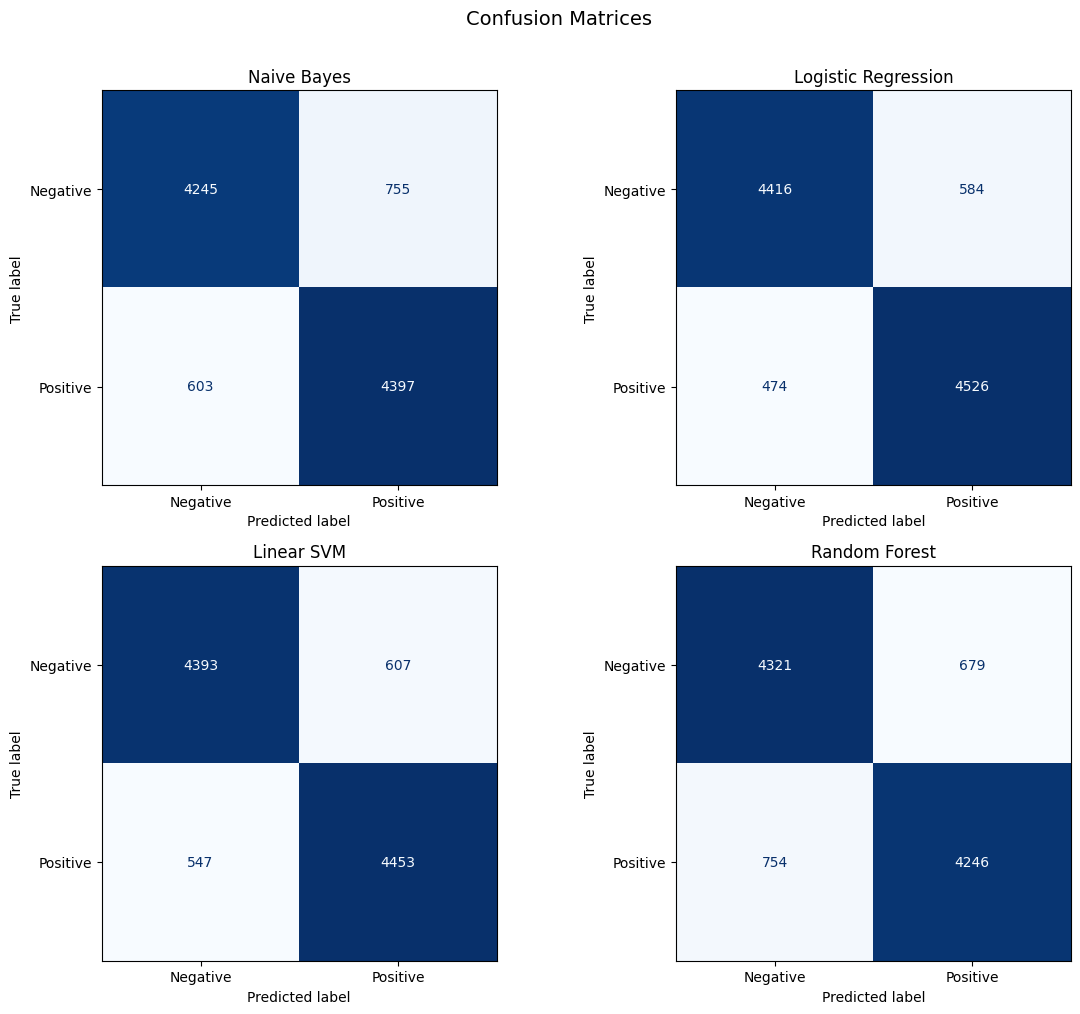

In [13]:
# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for idx, (name, pipe) in enumerate(pipelines.items()):
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive'])
    disp.plot(ax=axes.ravel()[idx], cmap='Blues', colorbar=False)
    axes.ravel()[idx].set_title(name)

plt.suptitle('Confusion Matrices', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

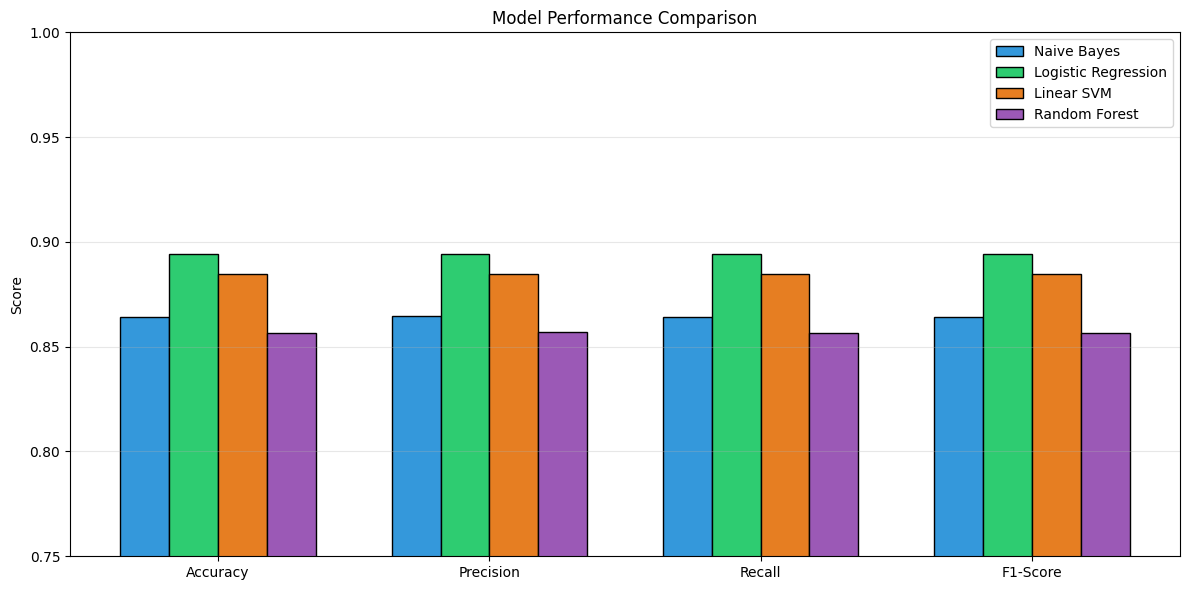

In [14]:
# Bar chart — compare models across metrics
fig, ax = plt.subplots(figsize=(12, 6))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.18
colors = ['#3498db', '#2ecc71', '#e67e22', '#9b59b6']

for i, (model_name, row) in enumerate(results_df.iterrows()):
    vals = [row[m] for m in metrics]
    ax.bar(x + i * width, vals, width, label=model_name, color=colors[i], edgecolor='black')

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.legend()
ax.set_ylim(0.75, 1.0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---
## Q3 — Hyperparameter Tuning

### Q3.1 — Hyperparameters

NB: alpha. LR: C. SVM: C. RF: n_estimators, max_depth. TF-IDF: max_features, ngram_range. See report Section 8.1.

In [15]:
# GridSearchCV — tune all 4 models
# Using a 10k subset for most models, 5k for Random Forest since it's way slower
X_train_sub = X_train.iloc[:10000]
y_train_sub = y_train.iloc[:10000]
X_train_sub_rf = X_train.iloc[:5000]
y_train_sub_rf = y_train.iloc[:5000]

param_grids = {
    'Naive Bayes': {
        'tfidf__max_features': [5000, 10000],
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'clf__alpha': [0.1, 0.5, 1.0]
    },
    'Logistic Regression': {
        'tfidf__max_features': [5000, 10000],
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'clf__C': [0.1, 1.0, 10.0]
    },
    'Linear SVM': {
        'tfidf__max_features': [5000, 10000],
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'clf__C': [0.1, 1.0, 10.0]
    },
    'Random Forest': {
        'tfidf__max_features': [5000, 10000],
        'clf__n_estimators': [100, 200],
        'clf__max_depth': [None, 10]
    }
}

tuned_results = []
best_models = {}

for name in pipelines:
    # RF gets smaller subset + fewer folds because it takes ages otherwise
    if name == 'Random Forest':
        sub_X, sub_y, cv = X_train_sub_rf, y_train_sub_rf, 3
    else:
        sub_X, sub_y, cv = X_train_sub, y_train_sub, 5

    print(f"Tuning {name}...", end=" ")
    gs = GridSearchCV(pipelines[name], param_grids[name],
                      cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(sub_X, sub_y)
    print(f"best params: {gs.best_params_}, CV F1: {gs.best_score_:.4f}")

    # Refit on full training data with best params
    best_pipe = gs.best_estimator_
    best_pipe.fit(X_train, y_train)
    y_pred = best_pipe.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')

    tuned_results.append({'Model': name, 'Accuracy': acc, 'Precision': prec,
                          'Recall': rec, 'F1-Score': f1})
    best_models[name] = best_pipe
    print(f"  -> Test acc: {acc:.4f}, F1: {f1:.4f}")

tuned_df = pd.DataFrame(tuned_results).set_index('Model')
print("\nTuned results:")
print(tuned_df.round(4).to_string())

Tuning Naive Bayes... 

best params: {'clf__alpha': 1.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}, CV F1: 0.8529


  -> Test acc: 0.8642, F1: 0.8642
Tuning Logistic Regression... 

best params: {'clf__C': 1.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 1)}, CV F1: 0.8763


  -> Test acc: 0.8920, F1: 0.8920
Tuning Linear SVM... 

best params: {'clf__C': 0.1, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}, CV F1: 0.8772


  -> Test acc: 0.8943, F1: 0.8943
Tuning Random Forest... 

best params: {'clf__max_depth': None, 'clf__n_estimators': 200, 'tfidf__max_features': 10000}, CV F1: 0.8380


  -> Test acc: 0.8595, F1: 0.8595

Tuned results:
                     Accuracy  Precision  Recall  F1-Score
Model                                                     
Naive Bayes            0.8642     0.8645  0.8642    0.8642
Logistic Regression    0.8920     0.8923  0.8920    0.8920
Linear SVM             0.8943     0.8945  0.8943    0.8943
Random Forest          0.8595     0.8595  0.8595    0.8595


                     Baseline Accuracy  Tuned Accuracy  Baseline F1  Tuned F1  Acc Change  F1 Change
Model                                                                                               
Naive Bayes                     0.8642          0.8642       0.8642    0.8642      0.0000     0.0000
Logistic Regression             0.8942          0.8920       0.8942    0.8920     -0.0022    -0.0022
Linear SVM                      0.8846          0.8943       0.8846    0.8943      0.0097     0.0097
Random Forest                   0.8567          0.8595       0.8567    0.8595      0.0028     0.0028


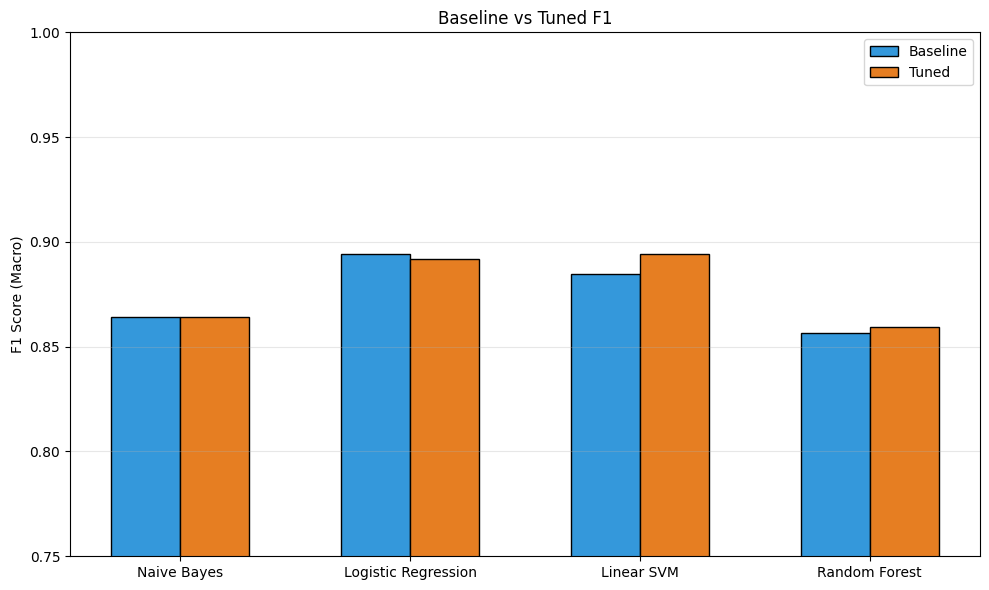

In [16]:
# Compare baseline vs tuned
comparison = pd.DataFrame({
    'Model': results_df.index,
    'Baseline Accuracy': results_df['Accuracy'].values,
    'Tuned Accuracy': tuned_df['Accuracy'].values,
    'Baseline F1': results_df['F1-Score'].values,
    'Tuned F1': tuned_df['F1-Score'].values,
}).set_index('Model')
comparison['Acc Change'] = comparison['Tuned Accuracy'] - comparison['Baseline Accuracy']
comparison['F1 Change'] = comparison['Tuned F1'] - comparison['Baseline F1']
print(comparison.round(4).to_string())

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(comparison))
w = 0.3
ax.bar(x - w/2, comparison['Baseline F1'], w, label='Baseline', color='#3498db', edgecolor='black')
ax.bar(x + w/2, comparison['Tuned F1'], w, label='Tuned', color='#e67e22', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(comparison.index, fontsize=10)
ax.set_ylabel('F1 Score (Macro)')
ax.set_title('Baseline vs Tuned F1')
ax.legend()
ax.set_ylim(0.75, 1.0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---
## Q4 — Discussion & Conclusion

### Q4.1 — Results Analysis

Linear models (SVM, LR) outperform NB and RF on sparse TF-IDF features. SVM benefits most from tuning (C=0.1). See report Section 9.

### Q4.2 — Comparison with Literature

Results are competitive with classical baselines (Maas et al. 83.8% NB vs our 86.4%). Gap to deep learning approaches (~95%) reflects TF-IDF limitations. See report Section 9.2.

### Q4.3 — Conclusion

Best model: Linear SVM at 89.43% F1. Future work: transformer-based models (BERT, RoBERTa). See report Section 9.4.